# Poda por similaridade de cosseno no GraphPFN: removendo as *k* camadas de menor BI

Este notebook aplica a **poda por cosseno** (Block Influence, ShortGPT) ao GraphPFN e compara cada modelo podado com o **modelo inteiro** (12 camadas).

$$BI_{\cos}(l) = 1 - \cos(h_l^{in}, h_l^{out})$$

Uma camada com BI baixo quase não altera sua entrada (age como identidade). A poda remove as camadas em ordem crescente de BI:

| Configuração | Camadas removidas |
|---|---|
| Inteiro | nenhuma (12 camadas) |
| k = 2 | as 2 camadas de menor BI |
| k = 3 | as 3 camadas de menor BI |
| … | … |
| k = 11 | as 11 camadas de menor BI (sobra 1) |

**Protocolo.** Mesmo pipeline do notebook `analise_camadas_e_poda_graphpfn.ipynb`: pré-processamento oficial (`predict_icl`), split oficial, 3 sementes pareadas, sem re-treino. O BI é medido sobre **todos os tokens** com o modelo inteiro, e o ranking é calculado **por dataset**.

**Métricas reportadas (teste):**

| Tarefa | Métricas | Melhor |
|---|---|---|
| Classificação binária (tolokers-2) | ROC-AUC, Average Precision | ↑ |
| Multiclasse (cora, pubmed) | Acurácia, F1-macro | ↑ |
| Regressão (city-roads-M, artnet-views) | R², MAE, RMSE | R² ↑, MAE/RMSE ↓ |

Cada configuração mostra o **valor da métrica** (média ± desvio-padrão em 3 sementes) e a **diferença (Δ) em relação ao modelo inteiro**, na mesma unidade da métrica.

## 0. Configuração

In [1]:
import os, sys, time, warnings
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
from pathlib import Path
from contextlib import contextmanager

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "src" / "graphpfn").exists() else cwd / "GraphFPN"
os.chdir(PROJECT_ROOT)  # LimiXWrapper procura ./checkpoints/LimiX-16M.ckpt
sys.path.insert(0, str(PROJECT_ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import dgl
import dgl.data
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, mean_squared_error
from IPython.display import display

from graphpfn import GraphDataset, GraphPFN, GraphPFNLight
from graphpfn.inference.preprocessing import prepare_features_tensor, prepare_graph, standardize_targets
from graphpfn.inference.util import apply_model, compute_metrics

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT = PROJECT_ROOT / "checkpoints" / "graphpfn-adapters-1_3.pt"
GRAPHLAND_ROOT = Path.home() / ".cache" / "graphland"
RESULTS_DIR = PROJECT_ROOT.parent / "Block_Influence_results" / "graphfpn_poda_cosseno_k"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

DATASETS = {
    "tolokers-2":   dict(source="graphland"),             # classificação binária
    "cora":         dict(source="planetoid", d_pca=64),   # multiclasse (7 classes)
    "pubmed":       dict(source="planetoid", d_pca=64),   # multiclasse (3 classes)
    "city-roads-M": dict(source="graphland"),             # regressão
    "artnet-views": dict(source="graphland"),             # regressão (~15 GB de GPU)
}
SEEDS = [0, 1, 2]
N_LAYERS = 12
K_LIST = list(range(2, N_LAYERS))   # remove as 2, 3, ..., 11 camadas de menor BI
BI_COL = "cos_all"                  # "cos_all" = todos os tokens (ShortGPT); "cos_tgt" = só o token-alvo
AMP = True
RECOMPUTE = False                   # True = ignora os CSVs em cache

PRIMARY_METRIC = {"binclass": "roc_auc", "multiclass": "accuracy", "regression": "r2"}
METRICS = {"binclass": ["roc_auc", "average_precision"],
           "multiclass": ["accuracy", "f1_macro"],
           "regression": ["r2", "mae", "rmse"]}
LOWER_IS_BETTER = {"mae", "rmse"}
METRIC_LABEL = {"roc_auc": "ROC-AUC", "average_precision": "AP", "accuracy": "Acurácia",
                "f1_macro": "F1-macro", "r2": "R²", "mae": "MAE", "rmse": "RMSE"}

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
GRAY = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
})
print(f"Dispositivo: {DEVICE} ({torch.cuda.get_device_name() if DEVICE.type == 'cuda' else 'cpu'})")
print(f"Resultados:  {RESULTS_DIR}")

Dispositivo: cuda (NVIDIA GeForce RTX 5060 Ti)
Resultados:  /home/isabelly/Documentos/Graph_Pruning/Block_Influence_results/graphfpn_poda_cosseno_k


## 1. Modelo, dados e funções de avaliação

In [2]:
BASE = GraphPFNLight()
BASE.load_state_dict(torch.load(CHECKPOINT, map_location="cpu", weights_only=True)["state_dict"], strict=False)
BASE = BASE.eval().to(DEVICE)
P_TOTAL = sum(p.numel() for p in BASE.parameters())
P_LAYER = sum(p.numel() for p in BASE.tfm.module.transformer_encoder.layers[0].parameters())

def get_layers(model):
    return model.base.tfm.module.transformer_encoder.layers

def load_dataset(name, cfg):
    if cfg["source"] == "graphland":
        return GraphDataset.from_graphland(name, root_dir=GRAPHLAND_ROOT / name / name / "raw")
    cls = {"cora": dgl.data.CoraGraphDataset, "pubmed": dgl.data.PubmedGraphDataset}[name]
    g = cls(verbose=False)[0]
    src, dst = g.edges()
    return GraphDataset(
        name=name,
        graph=dgl.graph((src, dst), num_nodes=g.num_nodes(), idtype=torch.int32),
        features={"other": g.ndata["feat"].numpy().astype(np.float32)},
        targets=g.ndata["label"].numpy().astype(np.float32),
        masks={k: g.ndata[f"{k}_mask"].numpy().astype(bool) for k in ["train", "val", "test"]},
        task_type="multiclass",
    )

def prepare_task(name, cfg):
    """Replica o pré-processamento de graphpfn.inference.icl.predict_icl."""
    ds = load_dataset(name, cfg)
    graph = prepare_graph(ds.graph).to(DEVICE)
    np.random.seed(0)  # o PCA do pacote usa SVD aleatorizado sem random_state: fixa para ser reprodutível
    features = prepare_features_tensor(ds.features, ds.masks["train"], d_pca=cfg.get("d_pca")).to(DEVICE)
    train_mask = torch.tensor(ds.masks["train"]).to(DEVICE)
    y_train = torch.tensor(ds.targets).to(DEVICE)[train_mask]
    stats = None
    if ds.task_type == "regression":
        y_train, stats = standardize_targets(y_train=y_train)
    else:
        y_train = y_train.long()
    if ds.task_type == "multiclass":
        y_te = ds.targets[ds.masks["test"]]
        chance = np.unique(y_te, return_counts=True)[1].max() / len(y_te)
    else:
        chance = {"binclass": 0.5, "regression": 0.0}[ds.task_type]
    model = GraphPFN(BASE, n_members=1, n_features=features.shape[1], n_classes=ds.n_classes,
                     device=DEVICE, verbose=False).eval()
    return dict(name=name, ds=ds, task=ds.task_type, graph=graph, features=features, train_mask=train_mask,
                y_train=y_train, stats=stats, metric=PRIMARY_METRIC[ds.task_type], chance=chance, model=model)

@contextmanager
def pruned(model, remove=()):
    """Remove camadas trocando a ModuleList (equivale a substituí-las pela identidade)."""
    stack = model.base.tfm.module.transformer_encoder
    full = stack.layers
    remove = set(int(i) for i in remove)
    stack.layers = nn.ModuleList([l for i, l in enumerate(full) if i not in remove])
    try:
        yield
    finally:
        stack.layers = full

@torch.no_grad()
def predict(t, seed):
    torch.manual_seed(seed)  # fixa features aleatórias e positional embedding: comparação pareada
    return apply_model(model=t["model"], dataset=t["ds"], graph=t["graph"], features=t["features"],
                       y_train=t["y_train"], train_mask=t["train_mask"],
                       regression_target_stats=t["stats"], amp=AMP, device=DEVICE)

def all_metrics(t, preds, split):
    m = t["ds"].masks[split]
    y, p = t["ds"].targets[m], preds[m]
    out = compute_metrics(y_true=y, y_pred=p, task_type=t["task"])
    if t["task"] == "multiclass":
        out["f1_macro"] = f1_score(y, p.argmax(-1), average="macro")
    elif t["task"] == "regression":
        out["rmse"] = float(np.sqrt(mean_squared_error(y, p)))
    return out

def evaluate(t, seed, remove=()):
    with pruned(t["model"], remove):
        preds = predict(t, seed)
    return {f"{split}_{k}": v for split in ["val", "test"] for k, v in all_metrics(t, preds, split).items()}

def cached(fname, fn):
    path = RESULTS_DIR / fname
    if path.exists() and not RECOMPUTE:
        print(f"(carregado do cache: {path.name})")
        return pd.read_csv(path)
    df = fn()
    df.to_csv(path, index=False)
    return df

TASKS = {name: prepare_task(name, cfg) for name, cfg in DATASETS.items()}
display(pd.DataFrame([{
    "Dataset": t["name"], "Tarefa": t["task"], "Nós": t["ds"].n_nodes, "Treino": int(t["ds"].masks["train"].sum()),
    "Teste": int(t["ds"].masks["test"].sum()), "Métricas": ", ".join(METRIC_LABEL[m] for m in METRICS[t["task"]]),
    "Acaso (métrica principal)": round(float(t["chance"]), 3),
} for t in TASKS.values()]))

,Dataset,Tarefa,Nós,Treino,Teste,Métricas,Acaso (métrica principal)
0,tolokers-2,binclass,11758,1175,9407,"ROC-AUC, AP",0.500
1,cora,multiclass,2708,140,1000,"Acurácia, F1-macro",0.319
2,pubmed,multiclass,19717,60,1000,"Acurácia, F1-macro",0.413
3,city-roads-M,regression,57073,3610,28886,"R², MAE, RMSE",0.000
4,artnet-views,regression,50405,5040,40324,"R², MAE, RMSE",0.000


## 2. Block Influence (cosseno) por camada

Um *hook* em cada camada mede $1 - \cos(h^{in}, h^{out})$ durante um forward do modelo inteiro, em blocos de 4096 nós para não guardar os tensores. A média é sobre as 3 sementes.

In [3]:
def bi_reduce(h_in, h_out, eval_pos, chunk=4096):
    a, b = h_in[0], h_out[0]
    s_all = n_all = s_tgt = n_tgt = 0.0
    for s in range(0, a.shape[0], chunk):
        cos = F.cosine_similarity(a[s:s + chunk].float(), b[s:s + chunk].float(), dim=-1).clamp(-1, 1)
        s_all += (1 - cos).sum().item(); n_all += cos.numel()
        is_test = torch.arange(s, s + cos.shape[0], device=cos.device) >= eval_pos
        ct = cos[is_test, -1]
        s_tgt += (1 - ct).sum().item(); n_tgt += ct.numel()
    return {"cos_all": s_all / n_all, "cos_tgt": s_tgt / max(n_tgt, 1)}

def run_bi():
    rows = []
    for name, t in TASKS.items():
        eval_pos = int(t["train_mask"].sum())
        for seed in SEEDS:
            hooks = [layer.register_forward_hook(
                        lambda m, a, kw, out, i=i: rows.append(dict(dataset=name, seed=seed, layer=i,
                                                                    **bi_reduce(a[0], out[0], eval_pos))),
                        with_kwargs=True)
                     for i, layer in enumerate(get_layers(t["model"]))]
            try:
                predict(t, seed)
            finally:
                for h in hooks:
                    h.remove()
    return pd.DataFrame(rows)

df_bi = cached("block_influence_cos.csv", run_bi)
bi = df_bi.groupby(["dataset", "layer"], sort=False)[["cos_all", "cos_tgt"]].mean().reset_index()
ORDER = {n: bi[bi.dataset == n].sort_values(BI_COL)["layer"].tolist() for n in TASKS}

display(bi.pivot(index="layer", columns="dataset", values=BI_COL)[list(TASKS)]
        .style.background_gradient(cmap="Blues", axis=0).format("{:.4f}")
        .set_caption(f"BI cosseno por camada ({BI_COL}); mais claro = menor BI = podada primeiro"))
display(pd.DataFrame({n: [ORDER[n][:k] for k in K_LIST] for n in TASKS},
                     index=pd.Index(K_LIST, name="k")).map(lambda l: str(sorted(l)))
        .style.set_caption("Camadas removidas em cada k (as k de menor BI)"))

(carregado do cache: block_influence_cos.csv)


dataset,tolokers-2,cora,pubmed,city-roads-M,artnet-views
layer,,,,,
0,0.1702,0.1325,0.1313,0.1790,0.1269
1,0.0467,0.0262,0.0299,0.0194,0.0134
2,0.0508,0.0612,0.0619,0.0474,0.0473
3,0.1128,0.1536,0.1599,0.1022,0.1039
4,0.0972,0.0995,0.1003,0.1206,0.1057
5,0.2597,0.2526,0.2516,0.2712,0.2821
6,0.3264,0.3259,0.3170,0.3244,0.3499
7,0.2106,0.2092,0.2220,0.2345,0.2229
8,0.3205,0.3256,0.3446,0.3284,0.3591


,tolokers-2,cora,pubmed,city-roads-M,artnet-views
k,,,,,
2,"[1, 2]","[1, 2]","[1, 2]","[1, 2]","[1, 2]"
3,"[1, 2, 4]","[1, 2, 4]","[1, 2, 4]","[1, 2, 3]","[1, 2, 3]"
4,"[1, 2, 3, 4]","[0, 1, 2, 4]","[0, 1, 2, 4]","[1, 2, 3, 4]","[1, 2, 3, 4]"
5,"[1, 2, 3, 4, 10]","[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]"
6,"[0, 1, 2, 3, 4, 10]","[0, 1, 2, 3, 4, 7]","[0, 1, 2, 3, 4, 7]","[0, 1, 2, 3, 4, 7]","[0, 1, 2, 3, 4, 7]"
7,"[0, 1, 2, 3, 4, 7, 10]","[0, 1, 2, 3, 4, 7, 10]","[0, 1, 2, 3, 4, 7, 10]","[0, 1, 2, 3, 4, 7, 10]","[0, 1, 2, 3, 4, 7, 10]"
8,"[0, 1, 2, 3, 4, 5, 7, 10]","[0, 1, 2, 3, 4, 5, 7, 10]","[0, 1, 2, 3, 4, 5, 7, 10]","[0, 1, 2, 3, 4, 5, 7, 10]","[0, 1, 2, 3, 4, 5, 7, 10]"
9,"[0, 1, 2, 3, 4, 5, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 10]"
10,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]","[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]"


## 3. Modelo inteiro × podado (k = 2 … 11)

In [4]:
def run_pruning():
    rows = []
    for name, t in TASKS.items():
        for k in [0] + K_LIST:
            remove = ORDER[name][:k]
            for seed in SEEDS:
                try:
                    rows.append(dict(dataset=name, k=k, seed=seed, removidas=str(sorted(remove)),
                                     **evaluate(t, seed, remove)))
                except torch.OutOfMemoryError:
                    torch.cuda.empty_cache()
                    print(f"⚠ {name}: sem memória de GPU (k={k}, seed={seed})")
    return pd.DataFrame(rows)

tic = time.time()
df_raw = cached("poda_cosseno_k.csv", run_pruning)
print(f"{len(df_raw)} avaliações em {time.time() - tic:.0f}s")

(carregado do cache: poda_cosseno_k.csv)
165 avaliações em 0s


### 3.1 Tabelas por dataset

Cada tabela mostra a média ± desvio-padrão (3 sementes) no **teste**. A coluna **Δ** é a diferença para o modelo inteiro na mesma métrica (para MAE/RMSE, Δ positivo = pior).

In [5]:
def table_for(name):
    t = TASKS[name]; d = df_raw[df_raw.dataset == name]
    g = d.groupby("k")
    tab = pd.DataFrame(index=g.size().index)
    tab["Configuração"] = ["Inteiro (12 camadas)" if k == 0 else f"Poda {k} menores" for k in tab.index]
    tab["Camadas removidas"] = g["removidas"].first().replace("[]", "—")
    tab["Camadas"] = N_LAYERS - tab.index
    tab["Parâmetros (M)"] = ((P_TOTAL - tab.index * P_LAYER) / 1e6).round(2)
    for m in METRICS[t["task"]]:
        mean, std = g[f"test_{m}"].mean(), g[f"test_{m}"].std()
        tab[METRIC_LABEL[m]] = [f"{a:.4f} ± {b:.4f}" for a, b in zip(mean, std)]
        tab[f"Δ {METRIC_LABEL[m]}"] = (mean - mean.loc[0]).round(4)
    return tab.reset_index(drop=True)

TABLES = {}
for name in TASKS:
    tab = table_for(name)
    TABLES[name] = tab
    tab.to_csv(RESULTS_DIR / f"tabela_{name}.csv", index=False)
    metric = METRIC_LABEL[TASKS[name]["metric"]]
    display(tab.style
            .format({c: "{:+.4f}" for c in tab.columns if c.startswith("Δ")})
            .hide(axis="index")
            .set_caption(f"{name} — métrica principal: {metric}, acaso = {TASKS[name]['chance']:.3f}"))

Configuração,Camadas removidas,Camadas,Parâmetros (M),ROC-AUC,Δ ROC-AUC,AP,Δ AP
Inteiro (12 camadas),—,12,20.090000,0.8595 ± 0.0006,+0.0000,0.6114 ± 0.0023,+0.0000
Poda 2 menores,"[1, 2]",10,16.840000,0.7858 ± 0.0050,-0.0737,0.4741 ± 0.0099,-0.1373
Poda 3 menores,"[1, 2, 4]",9,15.220000,0.7311 ± 0.0015,-0.1283,0.4113 ± 0.0025,-0.2001
Poda 4 menores,"[1, 2, 3, 4]",8,13.590000,0.7702 ± 0.0013,-0.0893,0.4506 ± 0.0039,-0.1608
Poda 5 menores,"[1, 2, 3, 4, 10]",7,11.970000,0.6584 ± 0.0114,-0.2011,0.3269 ± 0.0123,-0.2845
Poda 6 menores,"[0, 1, 2, 3, 4, 10]",6,10.350000,0.5976 ± 0.0087,-0.2618,0.2747 ± 0.0060,-0.3367
Poda 7 menores,"[0, 1, 2, 3, 4, 7, 10]",5,8.720000,0.3803 ± 0.0068,-0.4792,0.1696 ± 0.0022,-0.4418
Poda 8 menores,"[0, 1, 2, 3, 4, 5, 7, 10]",4,7.100000,0.4326 ± 0.0086,-0.4268,0.1883 ± 0.0028,-0.4231
Poda 9 menores,"[0, 1, 2, 3, 4, 5, 7, 8, 10]",3,5.470000,0.5287 ± 0.0004,-0.3308,0.2453 ± 0.0024,-0.3661
Poda 10 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]",2,3.850000,0.4760 ± 0.0063,-0.3835,0.2038 ± 0.0029,-0.4076


Configuração,Camadas removidas,Camadas,Parâmetros (M),Acurácia,Δ Acurácia,F1-macro,Δ F1-macro
Inteiro (12 camadas),—,12,20.090000,0.6683 ± 0.0098,+0.0000,0.6666 ± 0.0106,+0.0000
Poda 2 menores,"[1, 2]",10,16.840000,0.5923 ± 0.0021,-0.0760,0.5972 ± 0.0043,-0.0694
Poda 3 menores,"[1, 2, 4]",9,15.220000,0.4790 ± 0.0066,-0.1893,0.4933 ± 0.0035,-0.1733
Poda 4 menores,"[0, 1, 2, 4]",8,13.590000,0.0637 ± 0.0012,-0.6047,0.0253 ± 0.0037,-0.6413
Poda 5 menores,"[0, 1, 2, 3, 4]",7,11.970000,0.1547 ± 0.0015,-0.5137,0.0686 ± 0.0027,-0.5980
Poda 6 menores,"[0, 1, 2, 3, 4, 7]",6,10.350000,0.1300 ± 0.0000,-0.5383,0.0329 ± 0.0000,-0.6337
Poda 7 menores,"[0, 1, 2, 3, 4, 7, 10]",5,8.720000,0.0910 ± 0.0000,-0.5773,0.0238 ± 0.0000,-0.6427
Poda 8 menores,"[0, 1, 2, 3, 4, 5, 7, 10]",4,7.100000,0.1037 ± 0.0006,-0.5647,0.0288 ± 0.0017,-0.6378
Poda 9 menores,"[0, 1, 2, 3, 4, 5, 7, 8, 10]",3,5.470000,0.1030 ± 0.0000,-0.5653,0.0267 ± 0.0000,-0.6399
Poda 10 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]",2,3.850000,0.0640 ± 0.0000,-0.6043,0.0173 ± 0.0000,-0.6493


Configuração,Camadas removidas,Camadas,Parâmetros (M),Acurácia,Δ Acurácia,F1-macro,Δ F1-macro
Inteiro (12 camadas),—,12,20.090000,0.7140 ± 0.0095,+0.0000,0.7249 ± 0.0099,+0.0000
Poda 2 menores,"[1, 2]",10,16.840000,0.6267 ± 0.0179,-0.0873,0.6151 ± 0.0178,-0.1097
Poda 3 menores,"[1, 2, 4]",9,15.220000,0.6287 ± 0.0098,-0.0853,0.6294 ± 0.0121,-0.0955
Poda 4 menores,"[0, 1, 2, 4]",8,13.590000,0.4130 ± 0.0000,-0.3010,0.1949 ± 0.0000,-0.5300
Poda 5 menores,"[0, 1, 2, 3, 4]",7,11.970000,0.4060 ± 0.0000,-0.3080,0.1925 ± 0.0000,-0.5324
Poda 6 menores,"[0, 1, 2, 3, 4, 7]",6,10.350000,0.1800 ± 0.0000,-0.5340,0.1017 ± 0.0000,-0.6232
Poda 7 menores,"[0, 1, 2, 3, 4, 7, 10]",5,8.720000,0.4130 ± 0.0000,-0.3010,0.1949 ± 0.0000,-0.5300
Poda 8 menores,"[0, 1, 2, 3, 4, 5, 7, 10]",4,7.100000,0.4130 ± 0.0000,-0.3010,0.1949 ± 0.0000,-0.5300
Poda 9 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 10]",3,5.470000,0.4057 ± 0.0006,-0.3083,0.1924 ± 0.0002,-0.5325
Poda 10 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]",2,3.850000,0.4070 ± 0.0000,-0.3070,0.1928 ± 0.0000,-0.5320


Configuração,Camadas removidas,Camadas,Parâmetros (M),R²,Δ R²,MAE,Δ MAE,RMSE,Δ RMSE
Inteiro (12 camadas),—,12,20.090000,0.6404 ± 0.0006,+0.0000,1.9422 ± 0.0023,+0.0000,2.6013 ± 0.0022,+0.0000
Poda 2 menores,"[1, 2]",10,16.840000,0.5784 ± 0.0007,-0.0621,2.1025 ± 0.0009,+0.1603,2.8168 ± 0.0024,+0.2155
Poda 3 menores,"[1, 2, 3]",9,15.220000,0.5564 ± 0.0003,-0.0841,2.1888 ± 0.0013,+0.2465,2.8894 ± 0.0009,+0.2881
Poda 4 menores,"[1, 2, 3, 4]",8,13.590000,0.5009 ± 0.0022,-0.1395,2.3296 ± 0.0043,+0.3874,3.0647 ± 0.0068,+0.4634
Poda 5 menores,"[0, 1, 2, 3, 4]",7,11.970000,-0.3616 ± 0.0013,-1.0020,3.4145 ± 0.0020,+1.4723,5.0619 ± 0.0025,+2.4606
Poda 6 menores,"[0, 1, 2, 3, 4, 7]",6,10.350000,-0.1799 ± 0.0080,-0.8204,3.9063 ± 0.0201,+1.9641,4.7121 ± 0.0159,+2.1108
Poda 7 menores,"[0, 1, 2, 3, 4, 7, 10]",5,8.720000,-0.9722 ± 0.0034,-1.6126,5.4206 ± 0.0058,+3.4784,6.0920 ± 0.0052,+3.4907
Poda 8 menores,"[0, 1, 2, 3, 4, 5, 7, 10]",4,7.100000,-1.1406 ± 0.0107,-1.7810,5.7070 ± 0.0162,+3.7647,6.3468 ± 0.0159,+3.7455
Poda 9 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 10]",3,5.470000,-0.0833 ± 0.0035,-0.7237,3.6147 ± 0.0113,+1.6725,4.5150 ± 0.0074,+1.9137
Poda 10 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]",2,3.850000,-0.0305 ± 0.0006,-0.6709,3.4304 ± 0.0034,+1.4882,4.4037 ± 0.0013,+1.8024


Configuração,Camadas removidas,Camadas,Parâmetros (M),R²,Δ R²,MAE,Δ MAE,RMSE,Δ RMSE
Inteiro (12 camadas),—,12,20.090000,0.6209 ± 0.0004,+0.0000,0.8236 ± 0.0007,+0.0000,1.0510 ± 0.0006,+0.0000
Poda 2 menores,"[1, 2]",10,16.840000,0.5129 ± 0.0008,-0.1080,0.9478 ± 0.0007,+0.1242,1.1913 ± 0.0009,+0.1403
Poda 3 menores,"[1, 2, 3]",9,15.220000,0.5268 ± 0.0006,-0.0941,0.9353 ± 0.0006,+0.1117,1.1742 ± 0.0008,+0.1233
Poda 4 menores,"[1, 2, 3, 4]",8,13.590000,0.3917 ± 0.0006,-0.2292,1.0742 ± 0.0006,+0.2507,1.3313 ± 0.0007,+0.2803
Poda 5 menores,"[0, 1, 2, 3, 4]",7,11.970000,-0.3709 ± 0.0057,-0.9919,1.5849 ± 0.0035,+0.7614,1.9986 ± 0.0042,+0.9476
Poda 6 menores,"[0, 1, 2, 3, 4, 7]",6,10.350000,-0.2302 ± 0.0105,-0.8512,1.5467 ± 0.0072,+0.7231,1.8933 ± 0.0081,+0.8423
Poda 7 menores,"[0, 1, 2, 3, 4, 7, 10]",5,8.720000,-1.0004 ± 0.0054,-1.6214,2.0205 ± 0.0030,+1.1969,2.4142 ± 0.0033,+1.3633
Poda 8 menores,"[0, 1, 2, 3, 4, 5, 7, 10]",4,7.100000,-1.7628 ± 0.0056,-2.3837,2.4327 ± 0.0029,+1.6092,2.8372 ± 0.0029,+1.7862
Poda 9 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 10]",3,5.470000,-0.0787 ± 0.0037,-0.6996,1.4452 ± 0.0028,+0.6217,1.7728 ± 0.0030,+0.7218
Poda 10 menores,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 10]",2,3.850000,-0.0767 ± 0.0018,-0.6976,1.4204 ± 0.0007,+0.5969,1.7712 ± 0.0015,+0.7202


### 3.2 Resumo: valores de todas as métricas no teste (média de 3 sementes)

In [6]:
cols = {}
for n in TASKS:
    g = df_raw[df_raw.dataset == n].groupby("k")
    for m in METRICS[TASKS[n]["task"]]:
        cols[(n, METRIC_LABEL[m])] = g[f"test_{m}"].mean()
summary = pd.DataFrame(cols)
summary.columns = pd.MultiIndex.from_tuples(summary.columns, names=["dataset", "métrica"])
summary.index = ["Inteiro" if k == 0 else f"Poda {k} menores" for k in summary.index]
summary.to_csv(RESULTS_DIR / "resumo_valores.csv")
display(summary.style.format("{:.4f}").set_caption("Valores no teste: linha 'Inteiro' = modelo completo"))

### 3.3 Gráficos: cada métrica em função de k, com o modelo inteiro como referência

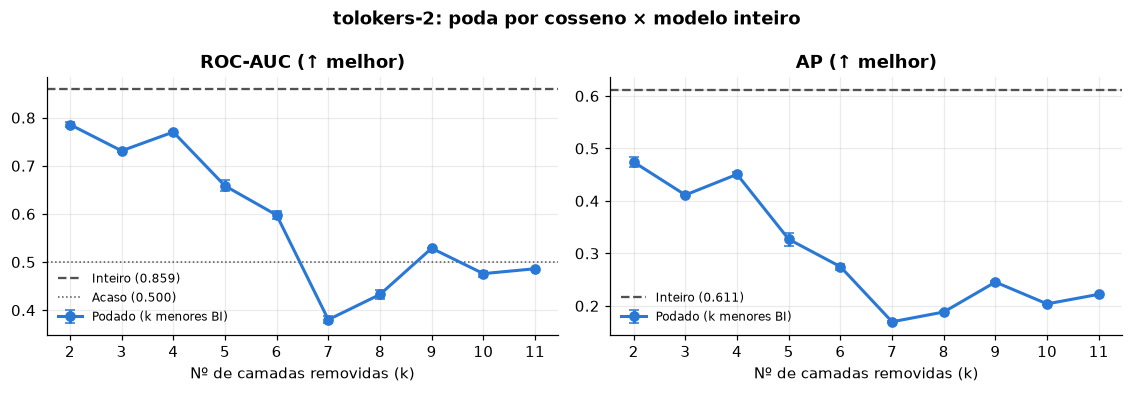

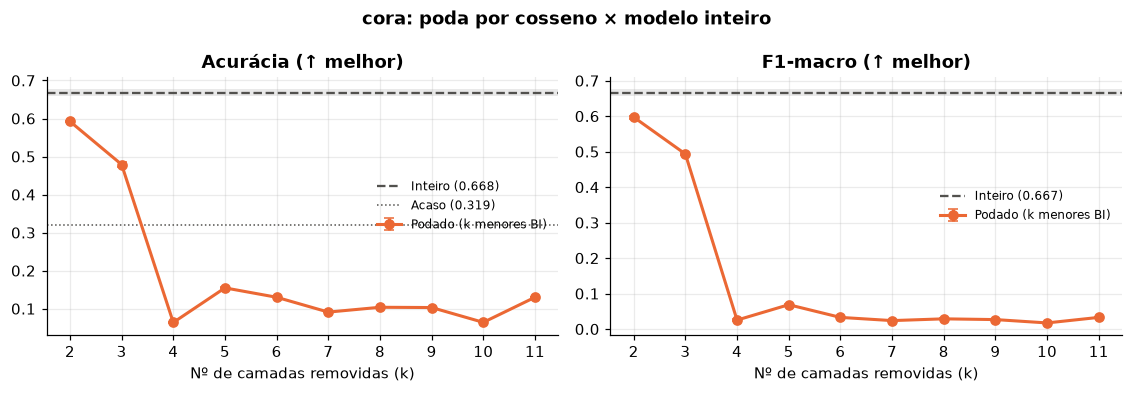

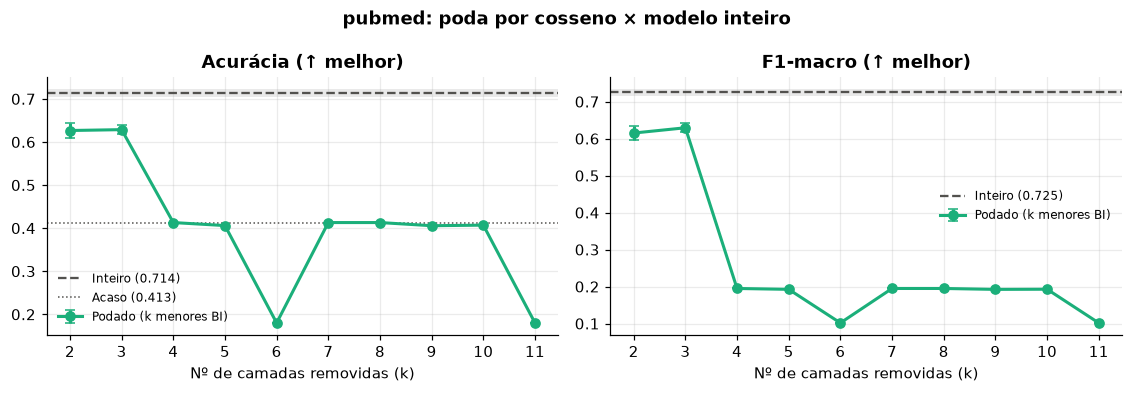

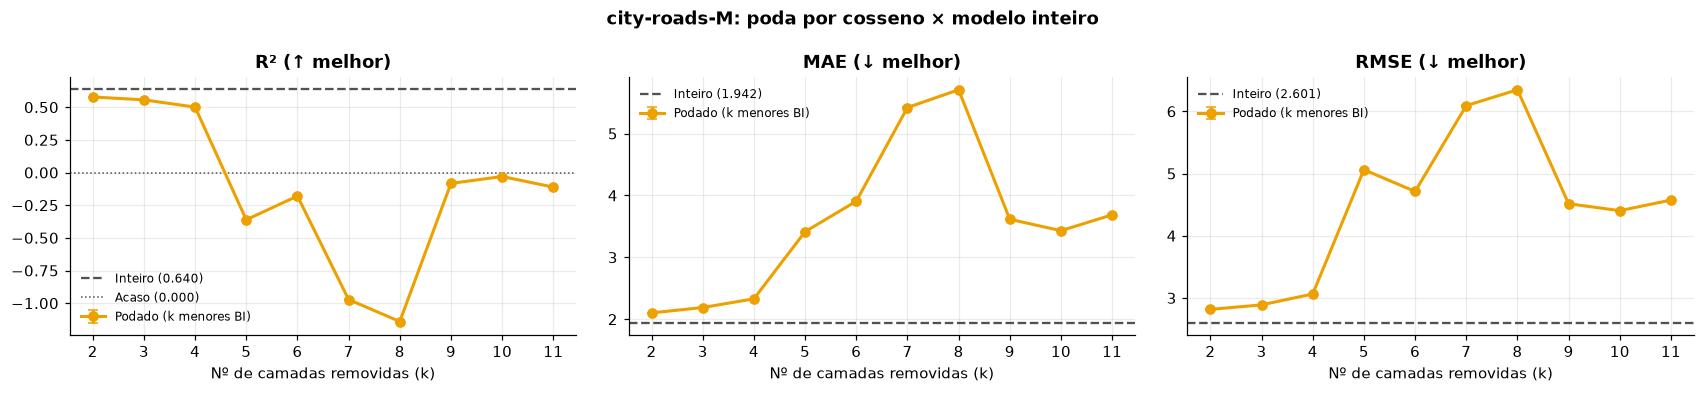

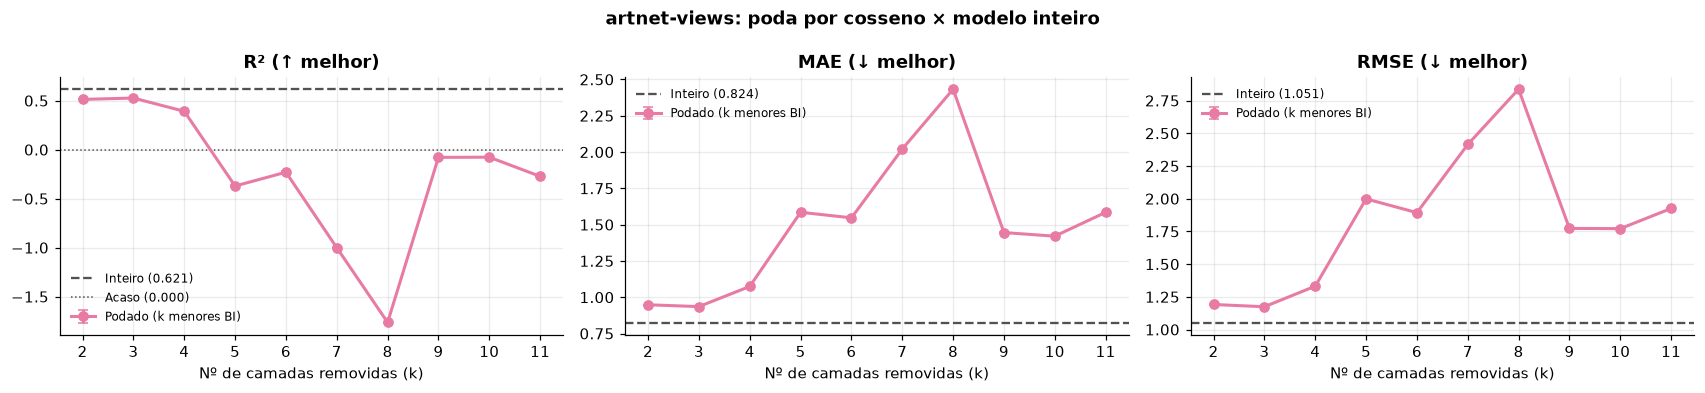

In [7]:
for j, name in enumerate(TASKS):
    t = TASKS[name]; d = df_raw[df_raw.dataset == name]
    ms = METRICS[t["task"]]
    fig, axes = plt.subplots(1, len(ms), figsize=(5.2 * len(ms), 3.6), squeeze=False)
    for ax, m in zip(axes[0], ms):
        g = d[d.k > 0].groupby("k")[f"test_{m}"]
        full = d[d.k == 0][f"test_{m}"]
        ax.axhspan(full.mean() - full.std(), full.mean() + full.std(), color=GRAY, alpha=0.12, lw=0)
        ax.axhline(full.mean(), color=GRAY, ls="--", lw=1.5, label=f"Inteiro ({full.mean():.3f})")
        if m == t["metric"]:
            ax.axhline(t["chance"], color=GRAY, ls=":", lw=1, label=f"Acaso ({t['chance']:.3f})")
        ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), marker="o", color=COLORS[j], capsize=3,
                    label="Podado (k menores BI)")
        ax.set_xticks(K_LIST)
        ax.set_xlabel("Nº de camadas removidas (k)")
        ax.set_title(METRIC_LABEL[m] + (" (↓ melhor)" if m in LOWER_IS_BETTER else " (↑ melhor)"))
        ax.legend(frameon=False, fontsize=8)
    fig.suptitle(f"{name}: poda por cosseno × modelo inteiro", fontweight="bold")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"metricas_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

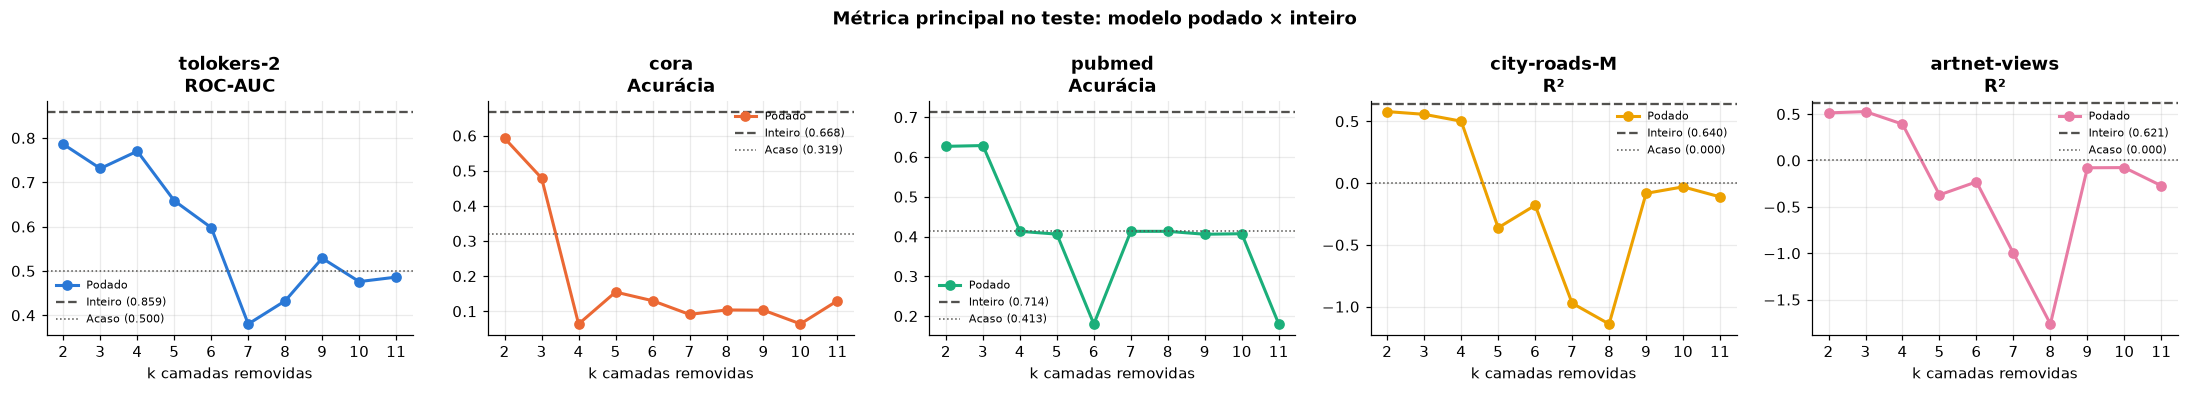

In [8]:
fig, axes = plt.subplots(1, len(TASKS), figsize=(4 * len(TASKS), 3.6))
for j, (ax, name) in enumerate(zip(axes, TASKS)):
    t = TASKS[name]
    y = df_raw[df_raw.dataset == name].groupby("k")[f"test_{t['metric']}"].mean()
    ax.plot(y.index[1:], y.values[1:], marker="o", color=COLORS[j], label="Podado")
    ax.axhline(y.loc[0], color=GRAY, ls="--", lw=1.5, label=f"Inteiro ({y.loc[0]:.3f})")
    ax.axhline(t["chance"], color=GRAY, ls=":", lw=1, label=f"Acaso ({t['chance']:.3f})")
    ax.set_xticks(K_LIST)
    ax.set_xlabel("k camadas removidas")
    ax.set_title(f"{name}\n{METRIC_LABEL[t['metric']]}")
    ax.legend(frameon=False, fontsize=7)
fig.suptitle("Métrica principal no teste: modelo podado × inteiro", fontweight="bold")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "metrica_principal_todos.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Conclusões

Valores no teste, média de 3 sementes (CSVs e figuras em `Block_Influence_results/graphfpn_poda_cosseno_k/`).

| Configuração | tolokers-2 ROC-AUC | tolokers-2 AP | cora Acurácia | cora F1-macro | pubmed Acurácia | pubmed F1-macro | city-roads-M R² | city-roads-M MAE | artnet-views R² | artnet-views MAE |
|---|---|---|---|---|---|---|---|---|---|---|
| **Inteiro** | **0,859** | **0,611** | **0,668** | **0,667** | **0,714** | **0,725** | **0,640** | **1,942** | **0,621** | **0,824** |
| Poda 2 menores | 0,786 | 0,474 | 0,592 | 0,597 | 0,627 | 0,615 | 0,578 | 2,102 | 0,513 | 0,948 |
| Poda 3 menores | 0,731 | 0,411 | 0,479 | 0,493 | 0,629 | 0,629 | 0,556 | 2,189 | 0,527 | 0,935 |
| Poda 4 menores | 0,770 | 0,451 | 0,064 | 0,025 | 0,413 | 0,195 | 0,501 | 2,330 | 0,392 | 1,074 |
| Poda 5 menores | 0,658 | 0,327 | 0,155 | 0,069 | 0,406 | 0,193 | −0,362 | 3,415 | −0,371 | 1,585 |
| Poda 6 menores | 0,598 | 0,275 | 0,130 | 0,033 | 0,180 | 0,102 | −0,180 | 3,906 | −0,230 | 1,547 |
| Poda 7 menores | 0,380 | 0,170 | 0,091 | 0,024 | 0,413 | 0,195 | −0,972 | 5,421 | −1,000 | 2,020 |
| Poda 8 menores | 0,433 | 0,188 | 0,104 | 0,029 | 0,413 | 0,195 | −1,141 | 5,707 | −1,763 | 2,433 |
| Poda 9 menores | 0,529 | 0,245 | 0,103 | 0,027 | 0,406 | 0,192 | −0,083 | 3,615 | −0,079 | 1,445 |
| Poda 10 menores | 0,476 | 0,204 | 0,064 | 0,017 | 0,407 | 0,193 | −0,031 | 3,430 | −0,077 | 1,420 |
| Poda 11 menores | 0,486 | 0,222 | 0,130 | 0,033 | 0,180 | 0,102 | −0,112 | 3,687 | −0,272 | 1,584 |

(RMSE de regressão e desvios-padrão nas tabelas da Seção 3.1.)

1. **Todas as podas pioram todas as métricas.** Nenhuma configuração podada iguala ou supera o modelo inteiro em nenhuma métrica.
2. **k = 2 e k = 3 são as únicas podas que ainda funcionam.** Elas removem as camadas 1, 2 e 3 ou 4 (−16% e −24% dos parâmetros). A menor perda é no city-roads-M com k = 2 (R² 0,640 → 0,578; MAE 1,94 → 2,10). Em classificação a queda já é grande: ROC-AUC 0,859 → 0,786 no tolokers-2, acurácia 0,668 → 0,592 no cora e 0,714 → 0,627 no pubmed.
3. **O colapso acontece quando a camada 0 entra na lista.** A camada 0 tem BI baixo na média de todos os tokens, mas é a que mais transforma o token-alvo. Ela é removida em k = 4 no cora e no pubmed e em k = 5 nos datasets de regressão. A partir daí o pubmed prevê só a classe majoritária (acurácia 0,413 = acaso, F1-macro 0,195), o cora fica abaixo do acaso (0,06–0,16) e o R² fica negativo.
4. **As curvas não são monótonas para k grande** (por exemplo, R² −1,14 em k = 8 e −0,03 em k = 10 no city-roads-M). Isso é ruído entre modelos já quebrados, não recuperação.

**Resumo:** a poda por cosseno das *k* camadas de menor BI, sem re-treino, não preserva o desempenho do GraphPFN para nenhum k ≥ 2. Se a poda continuar, vale (a) proteger a camada 0 (e a 1 em classificação), ou usar o BI do token-alvo (`BI_COL = "cos_tgt"`), e (b) recuperar o desempenho com fine-tuning curto após a poda.

*Nota de reprodutibilidade:* o PCA do pacote (`apply_d_reduction`) usa SVD aleatorizado sem `random_state`. Por isso o notebook fixa `np.random.seed(0)` antes do pré-processamento. Sem isso, o baseline do cora varia cerca de ±2 p.p. entre execuções.
